# L-SING with Monotonic KAN: an executable companion

**Run all computes the examples, trains the benchmark models, writes new data, and renders new plots.** Nothing below imports the manuscript's plots. The code demonstrates the spline and derivative claims alongside UMNN comparisons. In Colab, select a GPU runtime first if desired; CPU also works.

- `BENCHMARK_MODE = "quick"` (default): all six benchmark runners, reduced samples/epochs; expect different F1 scores from the paper. The ovarian comparison uses **12 genes**, not the full 156-gene network.
- `BENCHMARK_MODE = "full"`: full Gaussian, Butterfly, SM-KAN Butterfly, 40D Butterfly, ovarian and hardware runs. The full ovarian UMNN comparison may take tens of minutes and exceed a free Colab session.
- Fresh JSON, matrices, logs and PNGs are written to `results/kan_benchmarks/notebook_runs/<run-id>/` (also available in Colab's Files sidebar). The runner trains in an isolated copy so it cannot overwrite committed results. The notebook displays **only this run's data**.
- 40D UMNN is *projected from one measured row*, not a measured full precision matrix. Neither the numerical examples nor the plots constitute mathematical proofs; the paper supplies the proofs.

1. [Transport formulation and run controls](#1-transport-formulation-and-run-controls)
2. [Spline and theorem demonstrations](#2-spline-and-theorem-demonstrations)
3. [Measured profiling](#3-measured-profiling)
4. [Gaussian graph recovery](#4-gaussian-graph-recovery)
5. [Butterfly and scale modulation](#5-butterfly-and-scale-modulation)
6. [40D scaling and TCGA ovarian genes](#6-40d-scaling-and-tcga-ovarian-genes)
7. [Interpretation and files](#7-interpretation-and-files)

## 1. Transport formulation and run controls
For each target $k$, $S^k(x_{-k},\cdot)_\sharp\pi(x_k\mid x_{-k})=\mathcal N(0,1)$. The empirical generalized precision is $\widehat\Omega_{jk}=N^{-1}\sum_i |T_{jk}(x^{(i)})|$ where
$$T_{jk}=-S_jS_k-SS_{jk}+\frac{S_{jkk}S_k-S_{kk}S_{jk}}{S_k^2}.$$
UMNN obtains a monotone map by quadrature; the KAN core uses monotone B-splines, and SM-KAN adds $S^k=E(x_{-k})S^k_{\rm core}+\alpha(x_{-k})$ with positive bounded $E$. We derive the visualizations below from tensors and benchmark outputs, not paper image files.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Colab opens a GitHub notebook in /content rather than in its checkout.
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
REPO_ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents, Path("/content/lsing_sw"))
                  if (path / "theory/kan_transport.tex").is_file()), None)
if REPO_ROOT is None and IN_COLAB:
    import subprocess
    REPO_ROOT = Path("/content/lsing_sw")
    if REPO_ROOT.exists():
        raise FileNotFoundError(f"Existing {REPO_ROOT} is not the expected repository; restart with a fresh Colab runtime")
    subprocess.run(["git", "clone", "--depth", "1", "--branch", "feat/monotonic-kan-transport",
                    "https://github.com/StefanoFochesatto/lsing_sw.git", str(REPO_ROOT)], check=True)
if REPO_ROOT is None:
    raise FileNotFoundError("Run from the repository root or notebooks/ (or open in Colab)")
REPO_ROOT = REPO_ROOT.resolve()
for path in (REPO_ROOT, REPO_ROOT / "src"):
    if str(path) not in sys.path: sys.path.insert(0, str(path))
RESULTS = REPO_ROOT / "results/kan_benchmarks"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}. Benchmarks and plots below are recomputed on this runtime.")

Device: cpu. Benchmarks and plots below are recomputed on this runtime.


### Reproduction controls
The next cell launches **all** benchmark scripts at `quick` or `full` fidelity. A quick run is an executable smoke comparison, not a reproduction of full-data graph-recovery scores. Runners write in an isolated temporary checkout; the notebook copies every generated JSON, ovarian matrix and log into a persistent, separately named run directory. To reproduce the long paper protocol, change `BENCHMARK_MODE` to `"full"` and Run all. No run substitutes a stored result for a failed benchmark.

In [2]:
import shutil, subprocess, tempfile, time, uuid
from datetime import datetime, timezone

BENCHMARK_MODE = "quick"  # "quick" or "full"; both retrain and regenerate all plots
if BENCHMARK_MODE not in ("quick", "full"):
    raise ValueError("Choose quick or full")
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:6]
RUN_DIR = RESULTS / "notebook_runs" / run_id
RUN_DIR.mkdir(parents=True)
(RUN_DIR / "run_metadata.json").write_text(json.dumps({
    "mode": BENCHMARK_MODE, "device": str(device), "torch": torch.__version__,
    "python": sys.version.split()[0], "run_id": run_id,
    "note": "Fresh training; 40D UMNN full-matrix latency is projected from one row"
}, indent=2))
# Scripts derive their output root from __file__. Never run them in the source checkout.
_scratch = tempfile.TemporaryDirectory(prefix="lsing_benchmark_")
BENCHMARK_ROOT = Path(_scratch.name)
for folder in ("models", "src", "benchmarks", "data"):
    shutil.copytree(REPO_ROOT / folder, BENCHMARK_ROOT / folder,
                    ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
(BENCHMARK_ROOT / "results/kan_benchmarks").mkdir(parents=True)
RUN_DATA = {}


def run_benchmark(name, script, output, *, device_aware=True):
    flags = (["--device", device.type] if device_aware else []) + (["--quick"] if BENCHMARK_MODE == "quick" else [])
    command = [sys.executable, str(BENCHMARK_ROOT / "benchmarks" / script), *flags]
    log_path = RUN_DIR / f"{name}.log"
    env = dict(os.environ, PYTHONPATH=os.pathsep.join((str(BENCHMARK_ROOT), str(BENCHMARK_ROOT / "src"))))
    print(f"Training {name}: {script} {' '.join(flags)}", flush=True)
    start = time.perf_counter()
    try:
        with log_path.open("w") as log:
            subprocess.run(command, cwd=BENCHMARK_ROOT, env=env, stdout=log,
                           stderr=subprocess.STDOUT, check=True, timeout=7200)
    except (subprocess.CalledProcessError, subprocess.TimeoutExpired) as exc:
        raise RuntimeError(f"{name} failed; see {log_path}. Last lines:\n" +
                           "\n".join(log_path.read_text().splitlines()[-35:])) from exc
    source = BENCHMARK_ROOT / "results/kan_benchmarks" / ("quick" if BENCHMARK_MODE == "quick" else "") / output
    if not source.is_file(): raise FileNotFoundError(source)
    destination = RUN_DIR / output
    shutil.copy2(source, destination)
    RUN_DATA[output] = json.loads(destination.read_text())
    print(f"  {time.perf_counter()-start:.1f}s; wrote {destination.relative_to(REPO_ROOT)}", flush=True)


run_benchmark("gaussian", "run_gaussian.py", "gaussian_benchmark.json")
run_benchmark("butterfly", "run_butterfly_samples.py", "butterfly_sample_sizes.json")
run_benchmark("butterfly_sm", "run_scale_modulated_butterfly.py", "scale_modulated_butterfly_results.json")
run_benchmark("butterfly40", "run_butterfly_40d.py", "butterfly_40d.json")
run_benchmark("ovarian", "run_ovarian_analysis.py", "ovarian_results.json")
run_benchmark("hardware", "run_hardware_scaling.py", "hardware_scaling_results.json")
for matrix_name in ("ovarian_precision_matrix.txt", "ovarian_umnn_precision_matrix.txt"):
    source = BENCHMARK_ROOT / "results/kan_benchmarks" / ("quick" if BENCHMARK_MODE == "quick" else "") / matrix_name
    if not source.is_file(): raise FileNotFoundError(source)
    shutil.copy2(source, RUN_DIR / matrix_name)
print(f"All six runs complete. Data and logs: {RUN_DIR.relative_to(REPO_ROOT)}")


def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(RUN_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Training gaussian: run_gaussian.py --device cpu --quick


  12.0s; wrote results/kan_benchmarks/notebook_runs/20261105T230750Z_351429/gaussian_benchmark.json


Training butterfly: run_butterfly_samples.py --device cpu --quick


  11.9s; wrote results/kan_benchmarks/notebook_runs/20261105T230750Z_351429/butterfly_sample_sizes.json


Training butterfly_sm: run_scale_modulated_butterfly.py --device cpu --quick


  7.8s; wrote results/kan_benchmarks/notebook_runs/20261105T230750Z_351429/scale_modulated_butterfly_results.json


... (3 outputs left out)

  19.2s; wrote results/kan_benchmarks/notebook_runs/20261105T230750Z_351429/ovarian_results.json


Training hardware: run_hardware_scaling.py --device cpu --quick


  8.7s; wrote results/kan_benchmarks/notebook_runs/20261105T230750Z_351429/hardware_scaling_results.json


All six runs complete. Data and logs: results/kan_benchmarks/notebook_runs/20261105T230750Z_351429


## 2. Spline and theorem demonstrations
**Lemma 4.1.** Cubic B-splines with cumulative-softplus coefficients $c_m=c_1+\sum_{r<m}(\operatorname{softplus}(\theta_r)+\delta_{\rm mono})$ have positive first derivative on the knot domain. $C^1$ linear extrapolation carries positive boundary slopes into the tails. The code evaluates the actual `BSplineBasis` implementation over $[-8,8]$.

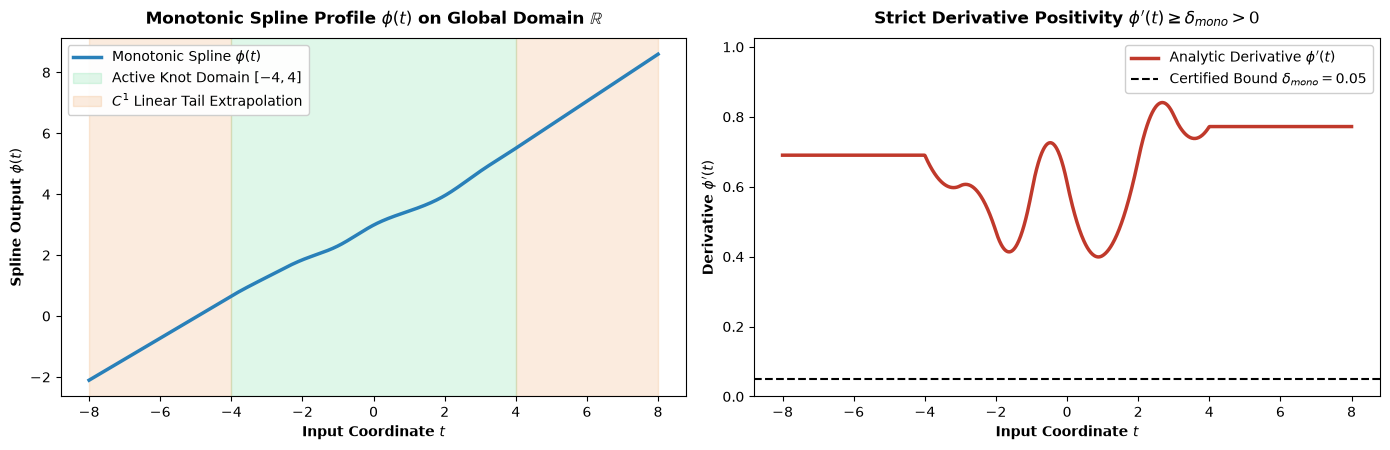

Lemma 4.1 Verification: Minimum spline derivative on [-8, 8] is 0.39922 > 0!


In [3]:
# Demonstration of Lemma 4.1: Cumulative Softplus & C^1 Linear Tail Extrapolation
from models.monotonic_kan import BSplineBasis

grid_min, grid_max = -4.0, 4.0
num_intervals = 8
spline_order = 3
grid = BSplineBasis.build_grid(grid_min, grid_max, num_intervals=num_intervals, degree=spline_order, device=device)
M = num_intervals + spline_order  # 11 control points
delta_mono = 0.05

# Random unconstrained parameters theta
torch.manual_seed(123)
theta = torch.randn(M, device=device)
c = torch.zeros(M, device=device)
c[0] = theta[0]
c[1:] = c[0] + torch.cumsum(torch.nn.functional.softplus(theta[1:]) + delta_mono, dim=0)

# Evaluate B-spline across interior and far extrapolation tails [-8, 8]
t_eval = torch.linspace(-8.0, 8.0, 1000, device=device).unsqueeze(1)
c_tensor = c.view(1, 1, M)

bases, d1, d2, d3 = BSplineBasis.eval_basis(t_eval, grid, spline_order)
phi = torch.sum(bases * c_tensor, dim=-1).squeeze().detach().cpu().numpy()
phi_p = torch.sum(d1 * c_tensor, dim=-1).squeeze().detach().cpu().numpy()
assert phi_p.min() >= delta_mono, "Spline monotonicity check failed"
t_cpu = t_eval.squeeze().detach().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# Panel 1: Profile phi(t)
axes[0].plot(t_cpu, phi, color="#2980b9", lw=2.5, label=r"Monotonic Spline $\phi(t)$")
axes[0].axvspan(grid_min, grid_max, color="#2ecc71", alpha=0.15, label="Active Knot Domain $[-4, 4]$")
axes[0].axvspan(-8, grid_min, color="#e67e22", alpha=0.15, label=r"$C^1$ Linear Tail Extrapolation")
axes[0].axvspan(grid_max, 8, color="#e67e22", alpha=0.15)
axes[0].set_title(r"Monotonic Spline Profile $\phi(t)$ on Global Domain $\mathbb{R}$", fontweight="bold", pad=10)
axes[0].set_xlabel("Input Coordinate $t$", fontweight="bold")
axes[0].set_ylabel(r"Spline Output $\phi(t)$", fontweight="bold")
axes[0].legend(loc="upper left", framealpha=0.95)

# Panel 2: Derivative phi'(t)
axes[1].plot(t_cpu, phi_p, color="#c0392b", lw=2.5, label=r"Analytic Derivative $\phi'(t)$")
axes[1].axhline(delta_mono, color="black", linestyle="--", label=rf"Certified Bound $\delta_{{mono}} = {delta_mono}$")
axes[1].set_title(r"Strict Derivative Positivity $\phi'(t) \geq \delta_{mono} > 0$", fontweight="bold", pad=10)
axes[1].set_xlabel("Input Coordinate $t$", fontweight="bold")
axes[1].set_ylabel(r"Derivative $\phi'(t)$", fontweight="bold")
axes[1].set_ylim(0, max(phi_p) * 1.22)
axes[1].legend(loc="upper right", framealpha=0.95)

plt.tight_layout()
save_plot(fig, "lemma_spline_and_derivative.png")
print(f"Lemma 4.1 Verification: Minimum spline derivative on [-8, 8] is {phi_p.min():.5f} > 0!")
np.savetxt(RUN_DIR / "lemma_spline_profile.csv", np.column_stack((t_cpu, phi, phi_p)),
           delimiter=",", header="t,phi,phi_prime", comments="")



### Theorem 4.4: active backbone
The implemented layer-by-layer derivative must dominate one certified positive target path: $\partial_k S^k(x)\ge D_{\mathcal P^*}(x)>0$. We evaluate a three-layer map well beyond its knot grid and **plot both quantities**. A sampled inequality check is an illustration of the theorem, not its proof.

L=3, active path=(1, 0, 0, 0), device=cpu
min partial_k S^k=6.645, min D_P*=0.1997, min dominance margin=6.24


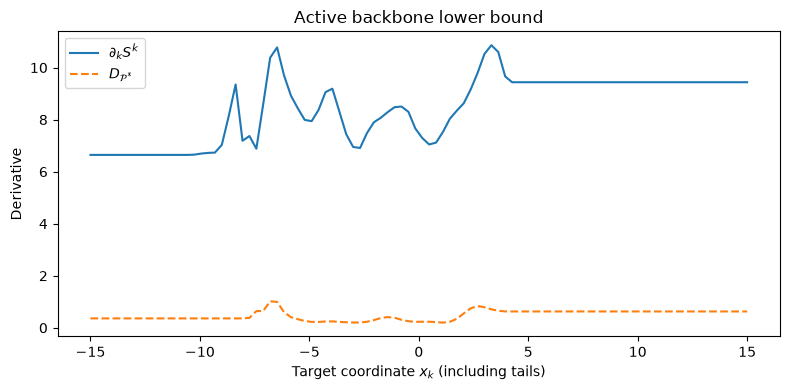

Interpretation: the dashed certified path remains positive, including outside the spline grid.


In [4]:
from models.monotonic_kan import MonotonicKANMap, ScaleModulatedKANMap

torch.manual_seed(321)
core = MonotonicKANMap(4, target_index=1, layers_hidden=[4, 5, 3, 1],
                       grid_size=8, eps_mono=0.05, dev=device).to(device)
core.randomize_parameters_(std=0.4, delta_std=0.6)
x_path = torch.linspace(-15, 15, 96, device=device).unsqueeze(1).repeat(1, 4)
with torch.no_grad():
    derivatives = core.compute_derivatives(x_path)
    slope = derivatives["S_k"].squeeze()
    path_slope = derivatives["S_k_backbone"].squeeze()
assert path_slope.min().item() > 0
assert (slope - path_slope).min().item() >= -1e-5
print(f"L={core.L}, active path={core.active_path}, device={device}")
print(f"min partial_k S^k={slope.min().item():.4g}, min D_P*={path_slope.min().item():.4g}, "
      f"min dominance margin={(slope-path_slope).min().item():.3g}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x_path[:, 1].cpu().numpy(), slope.cpu().numpy(), label=r"$\partial_k S^k$")
ax.plot(x_path[:, 1].cpu().numpy(), path_slope.cpu().numpy(), label=r"$D_{\mathcal{P}^*}$", ls="--")
ax.set(xlabel=r"Target coordinate $x_k$ (including tails)", ylabel="Derivative", title="Active backbone lower bound")
ax.legend()
save_plot(fig, "theorem_active_backbone.png")
np.savetxt(RUN_DIR / "theorem_backbone.csv", np.column_stack((x_path[:, 1].cpu().numpy(),
           slope.cpu().numpy(), path_slope.cpu().numpy())), delimiter=",",
           header="x_k,target_slope,backbone_slope", comments="")
print("Interpretation: the dashed certified path remains positive, including outside the spline grid.")

### Analytic Einstein recurrence versus autograd
`compute_derivatives` composes first, mixed second and mixed third derivatives via `torch.einsum`. The scatter compares the **per-sample precision integrand** against a float64 autograd reference, while `compute_precision_row` averages absolute integrands without retaining an autograd graph. This tests implementation accuracy; it is not a speed benchmark.

Precision integrand T_jk: max |analytic - float64 autograd| = 1.55e-15
Both calculations are per-sample; unlike the analytic evaluation, this reference builds an autograd graph.
Analytic precision row=[0.599 1.    0.526 0.764]; functional penalty=3.024; coefficient-group penalty=5.723


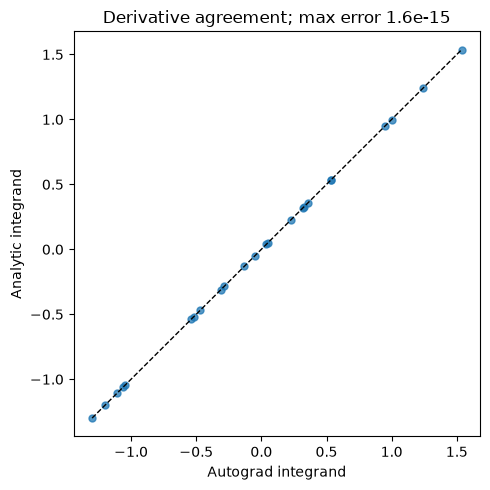

Interpretation: agreement on the identity line supports the analytic implementation on these samples.


In [5]:
torch.manual_seed(42)
check_model = MonotonicKANMap(4, target_index=1, hidden_dim=4, grid_size=8,
                              dev=device).to(dtype=torch.float64, device=device)
check_model.randomize_parameters_(std=0.3, delta_std=0.5)
x_check = torch.randn(8, 4, dtype=torch.float64, device=device, requires_grad=True)
parts = check_model.compute_derivatives(x_check)
S, Sk = parts["out"], parts["S_k"]
analytic = (-parts["S_all"] * Sk - S * parts["S_jk"] +
            (parts["S_jkk"] * Sk - parts["S_kk"] * parts["S_jk"]) / Sk.square())
log_conditional = -0.5 * S.square() + torch.log(Sk)
grad_k = torch.autograd.grad(log_conditional.sum(), x_check, create_graph=True)[0][:, 1]
autograd_row = torch.autograd.grad(grad_k.sum(), x_check)[0]
error = (analytic[:, check_model.other_indices] - autograd_row[:, check_model.other_indices]).abs().max().item()
assert error < 1e-9, error
print(f"Precision integrand T_jk: max |analytic - float64 autograd| = {error:.2e}")
print("Both calculations are per-sample; unlike the analytic evaluation, this reference builds an autograd graph.")

# Precision extraction reuses analytic derivatives under no_grad; no quadrature graph.
with torch.no_grad():
    row = check_model.compute_precision_row(x_check.detach())
    check_model.penalty_type = "functional"
    functional = check_model.compute_regularization(check_model.compute_derivatives(x_check.detach())["S_all"])
    check_model.penalty_type = "coeff_group"
    coefficient_group = check_model.compute_regularization()
    check_model.penalty_type = "functional"
assert row.shape == (4,) and row[1] == 1.0
print(f"Analytic precision row={np.round(row, 3)}; functional penalty={functional.item():.3f}; "
      f"coefficient-group penalty={coefficient_group.item():.3f}")

fig, ax = plt.subplots(figsize=(5, 5))
a = analytic[:, check_model.other_indices].detach().cpu().numpy().ravel()
b = autograd_row[:, check_model.other_indices].detach().cpu().numpy().ravel()
ax.scatter(b, a, s=25, alpha=.75)
lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
ax.plot([lo, hi], [lo, hi], "k--", lw=1)
ax.set(xlabel="Autograd integrand", ylabel="Analytic integrand", title=f"Derivative agreement; max error {error:.1e}")
save_plot(fig, "theorem_analytic_vs_autograd.png")
print("Interpretation: agreement on the identity line supports the analytic implementation on these samples.")
np.savetxt(RUN_DIR / "theorem_analytic_vs_autograd.csv", np.column_stack((a, b)),
           delimiter=",", header="analytic,autograd", comments="")

### Theorem 5.3: scale-modulated curvature cancellation
For $S=ES_{\rm core}+\alpha$, the ratio $(S_{jkk}S_k-S_{kk}S_{jk})/S_k^2$ cancels conditioning-scale contributions. We derive both sides from the actual SM-KAN layers, then plot their difference. The scale factor remains positive and the target derivative factorizes as $S_k=E(S_{\rm core})_k$.

E in [0.615, 1.688], max target-slope residual 0.00e+00, curvature cancellation residual 4.44e-16


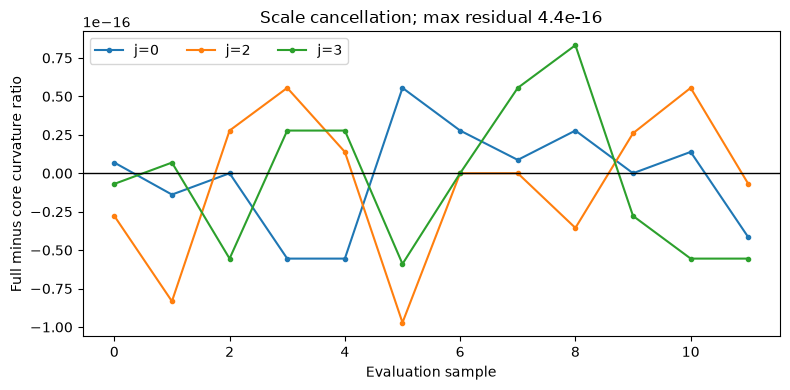

Interpretation: near-zero residuals show the scale terms cancel in the ratio, not in the full score.


In [6]:
torch.manual_seed(777)
sm = ScaleModulatedKANMap(4, target_index=1, hidden_dim=3, grid_size=8,
                          dev=device).to(dtype=torch.float64, device=device)
sm.randomize_parameters_(std=0.5, delta_std=0.6)
x_sm = torch.randn(12, 4, dtype=torch.float64, device=device)
with torch.no_grad():
    full = sm.compute_derivatives(x_sm)
    lhs = (full["S_jkk"] * full["S_k"] - full["S_kk"] * full["S_jk"]) / full["S_k"].square()
    acts, derivatives_per_layer = x_sm, []
    for layer in sm.core_layers:
        acts, p1, p2, p3 = layer.eval_splines_and_derivatives(acts)
        derivatives_per_layer.append((p1, p2, p3))
    A = torch.eye(4, dtype=x_sm.dtype, device=device).expand(len(x_sm), 4, 4)
    B, D = torch.zeros_like(A), torch.zeros_like(A)
    for p1, p2, p3 in derivatives_per_layer:
        Ak, Bk = A[:, :, 1], B[:, :, 1]
        A_next = torch.einsum('bai,bij->baj', p1, A)
        B_next = torch.einsum('bai,bi,bij->baj', p2, Ak, A) + torch.einsum('bai,bij->baj', p1, B)
        D_next = (torch.einsum('bai,bi,bij->baj', p3, Ak.square(), A) +
                  torch.einsum('bai,bij->baj', p2, Bk.unsqueeze(-1)*A + 2*Ak.unsqueeze(-1)*B) +
                  torch.einsum('bai,bij->baj', p1, D))
        A, B, D = A_next, B_next, D_next
    core_k, core_jk, core_jkk = A[:, :, 1], B.squeeze(1), D.squeeze(1)
    rhs = (core_jkk * core_k - core_jk[:, [1]] * core_jk) / core_k.square()
    residual = (lhs - rhs).abs().max().item()
    x_cond = x_sm[:, sm.other_indices]
    raw_scale = sm.scale_net(x_cond)
    E = torch.exp(sm.scale_bound * torch.tanh(raw_scale / sm.scale_bound))
    slope_error = (full["S_k"] - E * core_k).abs().max().item()
assert residual < 1e-9 and slope_error < 1e-9
print(f"E in [{E.min().item():.3f}, {E.max().item():.3f}], "
      f"max target-slope residual {slope_error:.2e}, curvature cancellation residual {residual:.2e}")

fig, ax = plt.subplots(figsize=(8, 4))
cancel = (lhs-rhs).detach().cpu().numpy()
for j in sm.other_indices:
    ax.plot(np.arange(len(cancel)), cancel[:, j], marker="o", ms=3, label=f"j={j}")
ax.axhline(0, color="black", lw=1)
ax.set(xlabel="Evaluation sample", ylabel="Full minus core curvature ratio",
       title=f"Scale cancellation; max residual {residual:.1e}")
ax.legend(ncol=3)
save_plot(fig, "theorem_scale_cancellation.png")
print("Interpretation: near-zero residuals show the scale terms cancel in the ratio, not in the full score.")
np.savetxt(RUN_DIR / "theorem_scale_cancellation.csv", cancel, delimiter=",")

### Computed Butterfly transport example
For the benchmark's paired variables $X\sim\mathcal N(0,1)$ and $Y=XW$, the ideal target map away from $X=0$ is $Z_Y=Y/|X|$. Below the bow-tie, slice-dependent slopes and transformed space are **redrawn from loaded test samples and this formula**. This is an ideal analytical example, not the output of an untrained SM-KAN.

Observed Y: mean=0.037, variance=0.983; ideal transported Z_Y: mean=0.024, variance=0.988
Ideal reference N(0,1) has mean=0, variance=1; 2000 samples retained.
Untrained SM-KAN batch: NLL=0.178, sparsity penalty=1.000, objective=0.188 (not a fitted transport)


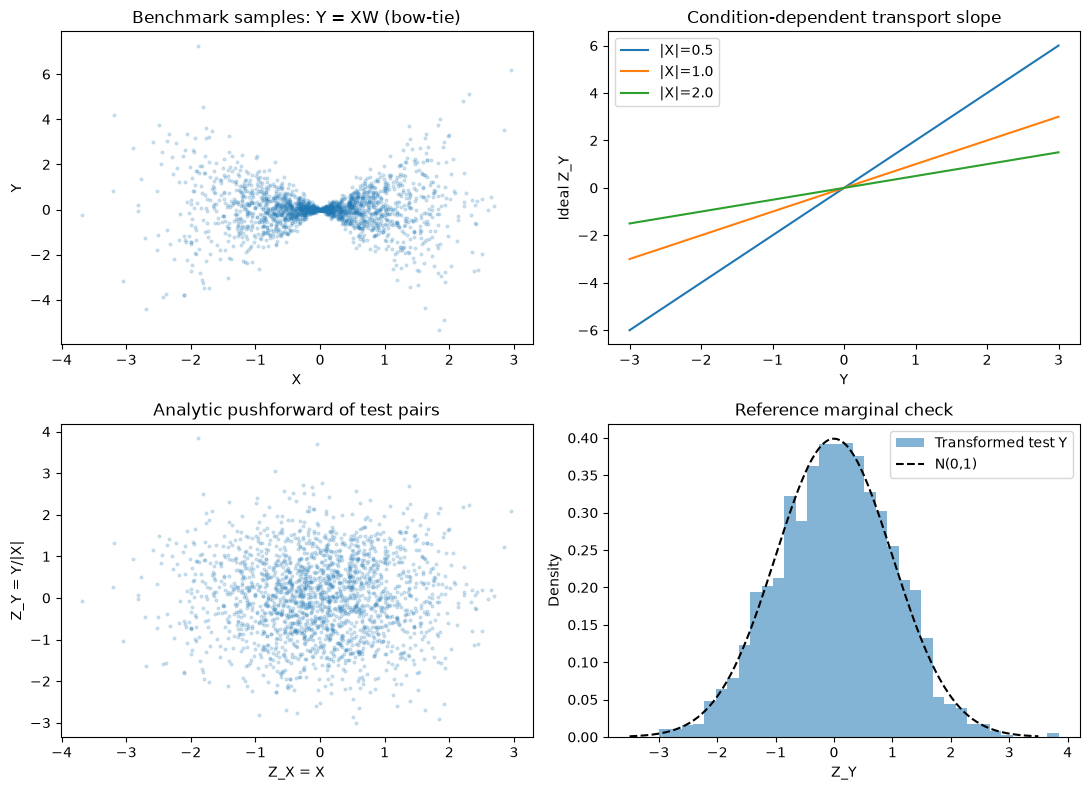

Interpretation: conditional rescaling removes the widening variance; the displayed moments quantify residual finite-sample error.


In [7]:
butterfly_samples = np.loadtxt(REPO_ROOT / "data/butterfly/bf_tst_10000_10d.txt", delimiter=",")[:2000, :2]
x_bf, y_bf = butterfly_samples[:, 0], butterfly_samples[:, 1]
mask = np.abs(x_bf) > 1e-8
z_bf = y_bf[mask] / np.abs(x_bf[mask])
print(f"Observed Y: mean={y_bf.mean():.3f}, variance={y_bf.var():.3f}; "
      f"ideal transported Z_Y: mean={z_bf.mean():.3f}, variance={z_bf.var():.3f}")
print(f"Ideal reference N(0,1) has mean=0, variance=1; {len(z_bf)} samples retained.")
example = ScaleModulatedKANMap(2, target_index=1, hidden_dim=3, grid_size=8, dev=device)
example_x = torch.as_tensor(butterfly_samples[:32], dtype=torch.float32, device=device)
loss, nll, regularizer = example.compute_loss(example_x, reg_value=0.01)
print(f"Untrained SM-KAN batch: NLL={nll.item():.3f}, sparsity penalty={regularizer.item():.3f}, "
      f"objective={loss.item():.3f} (not a fitted transport)")

from scipy.stats import norm
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0,0].scatter(x_bf, y_bf, s=4, alpha=.18)
axes[0,0].set(xlabel="X", ylabel="Y", title="Benchmark samples: Y = XW (bow-tie)")
y_grid = np.linspace(-3, 3, 100)
for x_slice in (.5, 1., 2.):
    axes[0,1].plot(y_grid, y_grid/x_slice, label=f"|X|={x_slice}")
axes[0,1].set(xlabel="Y", ylabel="Ideal Z_Y", title="Condition-dependent transport slope")
axes[0,1].legend()
axes[1,0].scatter(x_bf[mask], z_bf, s=4, alpha=.18)
axes[1,0].set(xlabel="Z_X = X", ylabel="Z_Y = Y/|X|", title="Analytic pushforward of test pairs")
axes[1,1].hist(z_bf, bins=35, density=True, alpha=.55, label="Transformed test Y")
t = np.linspace(-3.5, 3.5, 200)
axes[1,1].plot(t, norm.pdf(t), "k--", label="N(0,1)")
axes[1,1].set(xlabel="Z_Y", ylabel="Density", title="Reference marginal check")
axes[1,1].legend()
save_plot(fig, "butterfly_ideal_transport.png")
print("Interpretation: conditional rescaling removes the widening variance; the displayed moments quantify residual finite-sample error.")
np.savetxt(RUN_DIR / "butterfly_ideal_pushforward.csv", np.column_stack((x_bf[mask], y_bf[mask], z_bf)),
           delimiter=",", header="X,Y,Z_Y", comments="")

## 3. Measured profiling
The benchmark measures UMNN quadrature versus analytic KAN on **this runtime**. The training chart uses paired batch sizes and the precision-row chart uses the same evaluation batch; CUDA timings are not comparable to published CPU timings. Parameter counts depend on the tested model dimension/architecture. A projected or unoptimized UMNN bar is not silently treated as a full measured matrix.

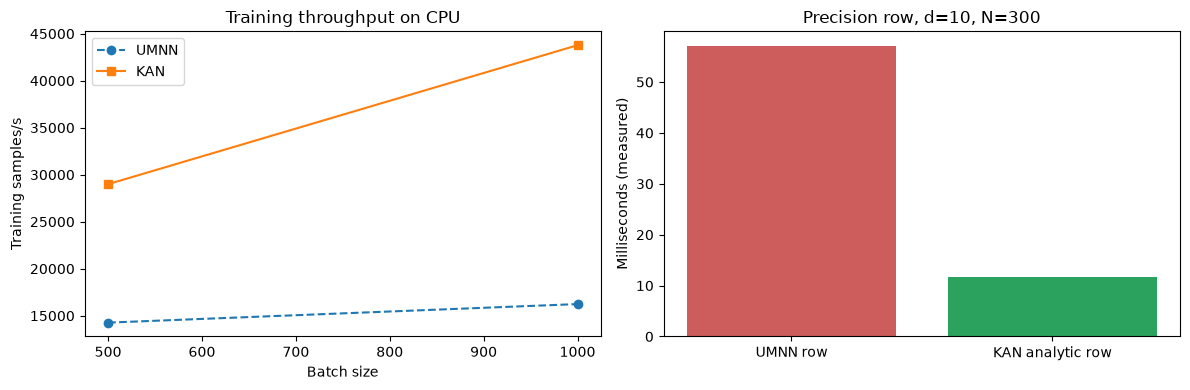

Measured d=10 parameter counts: UMNN=1,523, KAN=929; analytic row speedup=4.88x on cpu.
Interpretation: compare measured row latencies here, not manuscript full-matrix timings with different N.


In [8]:
hw = RUN_DATA["hardware_scaling_results.json"]
rows = sorted((r for r in hw["training_throughput"] if r["dim"] == 10), key=lambda r: r["batch_size"])
precision = next(r for r in hw["precision_evaluation"] if r["dim"] == 10)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
batches = [r["batch_size"] for r in rows]
axes[0].plot(batches, [r["umnn_samples_per_sec"] for r in rows], "o--", label="UMNN")
axes[0].plot(batches, [r["kan_samples_per_sec"] for r in rows], "s-", label="KAN")
axes[0].set(xlabel="Batch size", ylabel="Training samples/s", title=f"Training throughput on {device.type.upper()}")
axes[0].legend()
axes[1].bar(["UMNN row", "KAN analytic row"],
            [precision["umnn_fast_ms"], precision["kan_analytic_ms"]], color=["#cd5c5c", "#2ca25f"])
axes[1].set(ylabel="Milliseconds (measured)", title=f"Precision row, d=10, N={precision['n_eval_samples']}")
save_plot(fig, "measured_hardware_profile.png")
print(f"Measured d=10 parameter counts: UMNN={precision['umnn_params']:,}, KAN={precision['kan_params']:,}; "
      f"analytic row speedup={precision['kan_speedup_vs_umnn_fast']:.2f}x on {device}.")
print("Interpretation: compare measured row latencies here, not manuscript full-matrix timings with different N.")

## 4. Gaussian graph recovery
The benchmark trains UMNN and an additive monotonic KAN on the same Gaussian splits. The four true undirected edges are $(0,4),(2,6),(5,7),(6,9)$. Heatmaps and threshold curves below come from the **newly trained models**, not a published chart. With quick-mode training, low F1 is an expected underfitting signal rather than a contradiction of full-run claims.

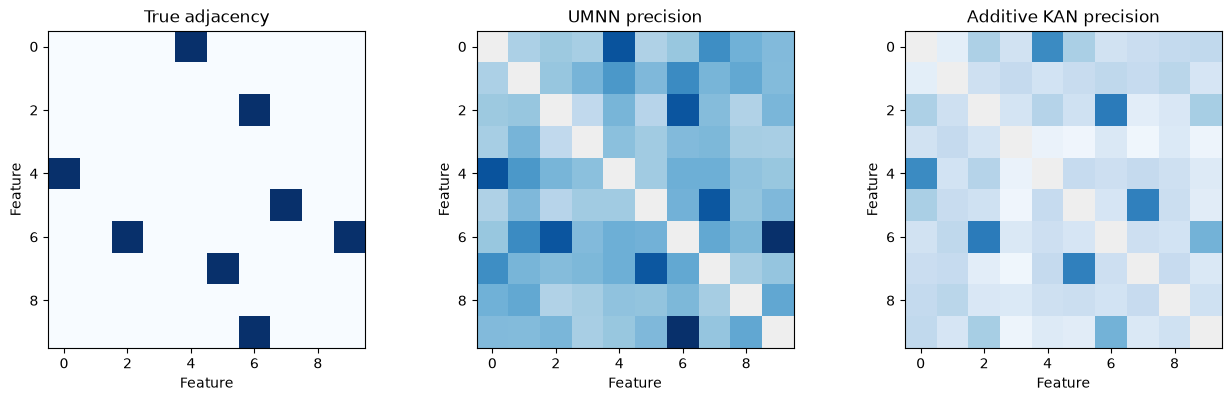

UMNN: F1@0.10=0.800, FP=2, FPR=0.049; precision evaluation=0.295s
KAN: F1@0.10=0.857, FP=0, FPR=0.000; precision evaluation=0.071s


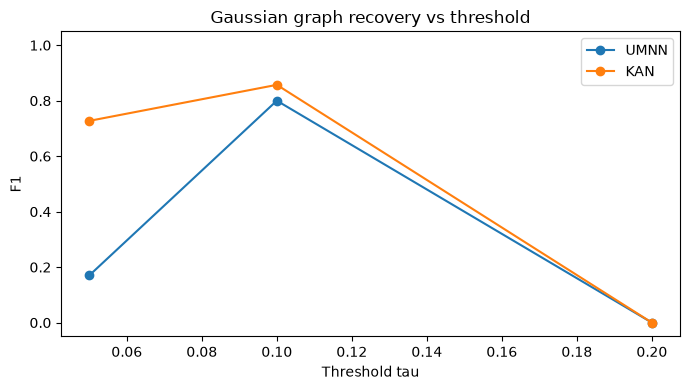

Interpretation: the same threshold can behave differently after quick versus full training; count false edges, not just F1.


In [9]:
gaussian = RUN_DATA["gaussian_benchmark.json"]
truth = np.zeros((10, 10))
for i, j in ((0, 4), (2, 6), (5, 7), (6, 9)):
    truth[i, j] = truth[j, i] = 1
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
offdiag = np.triu_indices(10, 1)
scale = max(np.abs(np.asarray(gaussian[key]["precision_matrix"])[offdiag]).max()
            for key in ("UMNN", "MonotonicKAN_Functional"))
cmap = plt.cm.Blues.copy(); cmap.set_bad("#eeeeee")
for ax, title, matrix in zip(axes, ("True adjacency", "UMNN precision", "Additive KAN precision"),
                             (truth, gaussian["UMNN"]["precision_matrix"],
                              gaussian["MonotonicKAN_Functional"]["precision_matrix"])):
    visible = np.abs(np.asarray(matrix, dtype=float)).copy()
    if title != "True adjacency": np.fill_diagonal(visible, np.nan)
    ax.imshow(visible, cmap=cmap, vmin=0, vmax=1 if title == "True adjacency" else scale)
    ax.set(title=title, xlabel="Feature", ylabel="Feature")
save_plot(fig, "gaussian_precision_heatmaps.png")
fig, ax = plt.subplots(figsize=(7, 4))
for key, label in (("UMNN", "UMNN"), ("MonotonicKAN_Functional", "KAN")):
    metrics = gaussian[key]["metrics"]
    tau = sorted(map(float, metrics))
    ax.plot(tau, [metrics[str(v)]["f1"] for v in tau], "o-", label=label)
    s = metrics["0.1"]
    print(f"{label}: F1@0.10={s['f1']:.3f}, FP={s['fp']}, FPR={s['fpr']:.3f}; "
          f"precision evaluation={gaussian[key]['eval_time_sec']:.3f}s")
ax.set(xlabel="Threshold tau", ylabel="F1", ylim=(-.05, 1.05), title="Gaussian graph recovery vs threshold")
ax.legend()
save_plot(fig, "gaussian_f1_by_threshold.png")
print("Interpretation: the same threshold can behave differently after quick versus full training; count false edges, not just F1.")

## 5. Butterfly and scale modulation
The sample-size runner trains **UMNN and additive KAN** on the same $d=10$ Butterfly data. A separate SM-KAN runner trains on the same stored dataset (for quick mode, $M=1000$, 200 evaluation samples and five epochs). We plot the generated metrics and SM-KAN precision matrix. Multiplicative heteroscedasticity can suppress the signal in an additive KAN; finite-sample quick runs need not recover all five true pairs.

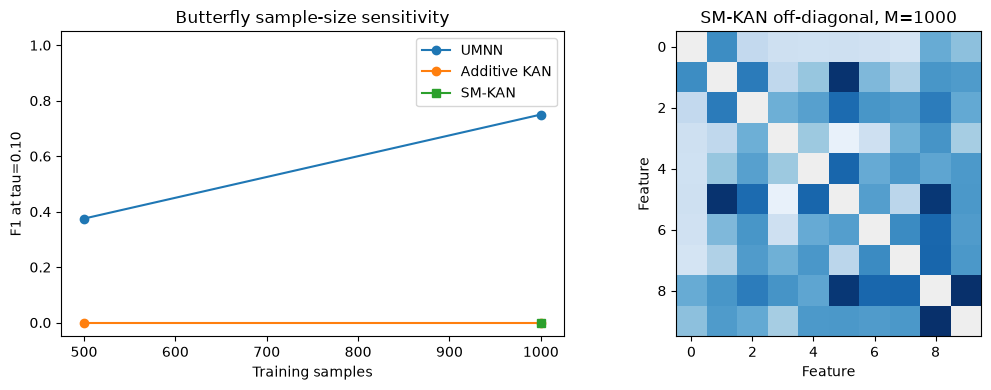

UMNN: F1=0.750, FP=0, FPR=0.000, precision extraction=0.314s (M=1000)
Additive KAN: F1=0.000, FP=0, FPR=0.000, precision extraction=0.077s (M=1000)
SM-KAN: F1=0.000, FP=0, FPR=0.000, precision extraction=0.356s (M=1000)
Interpretation: at this M, SM-KAN did not beat UMNN by F1; quick-run underfitting is not an architectural verdict.


In [10]:
butterfly = RUN_DATA["butterfly_sample_sizes.json"]
sm_results = RUN_DATA["scale_modulated_butterfly_results.json"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for key, label in (("UMNN", "UMNN"), ("MonotonicKAN_Functional", "Additive KAN")):
    sizes = sorted(map(int, butterfly))
    axes[0].plot(sizes, [butterfly[str(m)][key]["metrics"]["0.1"]["f1"] for m in sizes], "o-", label=label)
sm_sizes = sorted(map(int, sm_results))
axes[0].plot(sm_sizes, [sm_results[str(m)]["ScaleModulatedKAN"]["metrics"]["0.1"]["f1"] for m in sm_sizes],
             "s-", label="SM-KAN")
axes[0].set(xlabel="Training samples", ylabel="F1 at tau=0.10", ylim=(-.05, 1.05), title="Butterfly sample-size sensitivity")
axes[0].legend()
M = str(max(sm_sizes))
sm_entry = sm_results[M]["ScaleModulatedKAN"]
sm_visible = np.abs(np.asarray(sm_entry["precision_matrix"], dtype=float))
np.fill_diagonal(sm_visible, np.nan)
cmap = plt.cm.Blues.copy(); cmap.set_bad("#eeeeee")
axes[1].imshow(sm_visible, cmap=cmap, vmin=0, vmax=max(np.nanmax(sm_visible), .01))
axes[1].set(xlabel="Feature", ylabel="Feature", title=f"SM-KAN off-diagonal, M={M}")
save_plot(fig, "butterfly_graph_recovery.png")
for name, entry in (("UMNN", butterfly[M]["UMNN"]), ("Additive KAN", butterfly[M]["MonotonicKAN_Functional"]),
                    ("SM-KAN", sm_entry)):
    metric = entry["metrics"]["0.1"]
    print(f"{name}: F1={metric['f1']:.3f}, FP={metric['fp']}, FPR={metric['fpr']:.3f}, "
          f"precision extraction={entry['eval_time_sec']:.3f}s (M={M})")
print("Interpretation: at this M, SM-KAN " +
      ("improved over" if sm_entry["metrics"]["0.1"]["f1"] > butterfly[M]["UMNN"]["metrics"]["0.1"]["f1"] else
       "did not beat") + " UMNN by F1; quick-run underfitting is not an architectural verdict.")

## 6. 40D scaling and TCGA ovarian genes
In 40D there are 20 true pairs among $\binom{40}{2}=780$ candidate edges. The runner computes the full KAN matrix but measures UMNN on **one row** and projects its full-matrix latency for the same evaluation N. The heatmap below is generated from the KAN run, not a paper image.

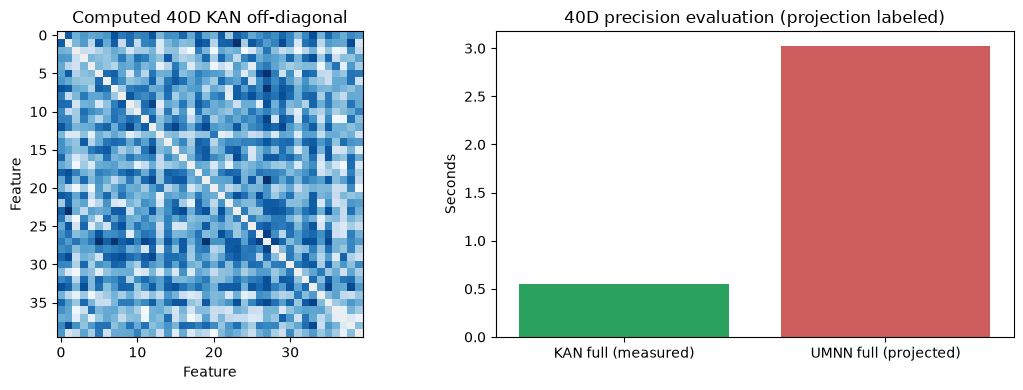

KAN full matrix measured=0.545s, F1@0.1=0.000; UMNN projected=3.025s. One UMNN row measured on N=200; projected to d=40 rows and N=200, not a full UMNN evaluation
Interpretation: projection quantifies possible scaling but does not establish a measured 40D UMNN speedup.


In [11]:
d40 = RUN_DATA["butterfly_40d.json"]
kan40 = d40["MonotonicKAN"]
um40 = d40["UMNN_Projected"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
visible40 = np.abs(np.asarray(kan40["precision_matrix"], dtype=float))
np.fill_diagonal(visible40, np.nan)
cmap = plt.cm.Blues.copy(); cmap.set_bad("#eeeeee")
axes[0].imshow(visible40, cmap=cmap, vmin=0, vmax=max(np.nanmax(visible40), .01))
axes[0].set(title="Computed 40D KAN off-diagonal", xlabel="Feature", ylabel="Feature")
axes[1].bar(["KAN full (measured)", "UMNN full (projected)"],
            [kan40["eval_time_sec"], um40["eval_time_sec"]], color=["#2ca25f", "#cd5c5c"])
axes[1].set(ylabel="Seconds", title="40D precision evaluation (projection labeled)")
save_plot(fig, "butterfly_40d_precision_and_latency.png")
print(f"KAN full matrix measured={kan40['eval_time_sec']:.3f}s, F1@0.1={kan40['metrics']['0.1']['f1']:.3f}; "
      f"UMNN projected={um40['eval_time_sec']:.3f}s. {um40['note']}")
print("Interpretation: projection quantifies possible scaling but does not establish a measured 40D UMNN speedup.")

### TCGA ovarian genes: 12-gene quick subset or full 156-gene network
The source data contain 578 patient samples (346 train, 115 validation, 117 test). The default quick run includes CTSE and EPCAM among 12 selected genes; **its hub rankings are not clinical validation**. `full` trains all 156 genes and 12,090 undirected pairs. UMNN and SM-KAN matrices plotted here are from the *same current run*; density is measured from their off-diagonal entries, not reconstructed from a stored paper figure.

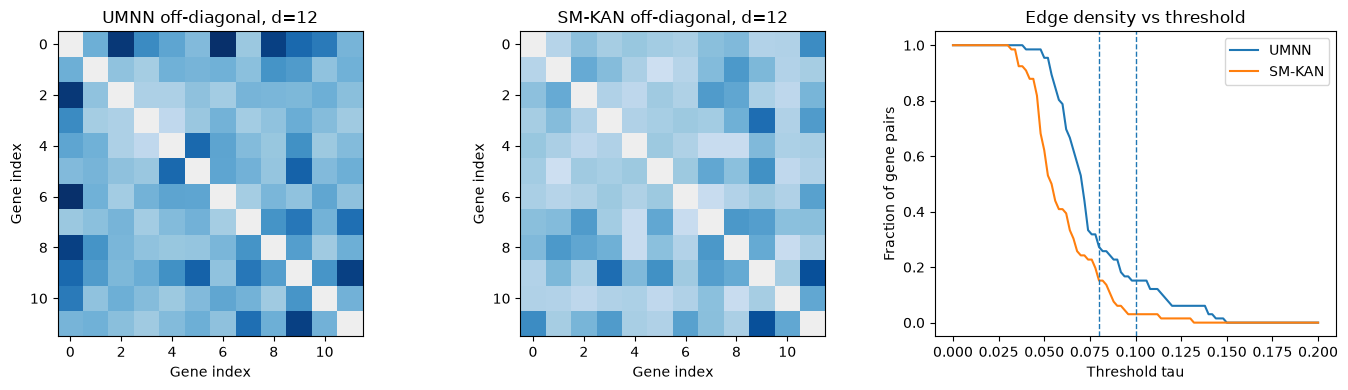

Same d=12 and N=117 test patients: UMNN=0.579s, SM-KAN=0.189s
Precision-entry Spearman rho=0.282; CTSE rank=12, EPCAM rank=5
Interpretation: thresholding changes edge density; rank agreement between methods is not a clinical ground truth.


In [12]:
ovarian_info = RUN_DATA["ovarian_results.json"]
d = ovarian_info["num_genes"]
umnn_matrix = np.loadtxt(RUN_DIR / "ovarian_umnn_precision_matrix.txt", delimiter=",")
kan_matrix = np.loadtxt(RUN_DIR / "ovarian_precision_matrix.txt", delimiter=",")
assert umnn_matrix.shape == kan_matrix.shape == (d, d)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
tri = np.triu_indices(d, 1)
shared_scale = max(np.abs(umnn_matrix[tri]).max(), np.abs(kan_matrix[tri]).max(), .01)
cmap = plt.cm.Blues.copy(); cmap.set_bad("#eeeeee")
for ax, matrix, label in ((axes[0], umnn_matrix, "UMNN"), (axes[1], kan_matrix, "SM-KAN")):
    visible = np.abs(matrix).copy()
    np.fill_diagonal(visible, np.nan)
    ax.imshow(visible, cmap=cmap, vmin=0, vmax=shared_scale)
    ax.set(title=f"{label} off-diagonal, d={d}", xlabel="Gene index", ylabel="Gene index")
tau = np.linspace(0, .2, 101)
tri = np.triu_indices(d, 1)
for matrix, label in ((umnn_matrix, "UMNN"), (kan_matrix, "SM-KAN")):
    upper = np.abs(matrix[tri])
    axes[2].plot(tau, [(upper > threshold).mean() for threshold in tau], label=label)
for threshold in (.08, .10): axes[2].axvline(threshold, ls="--", lw=1)
axes[2].set(title="Edge density vs threshold", xlabel="Threshold tau", ylabel="Fraction of gene pairs")
axes[2].legend()
save_plot(fig, "ovarian_precision_and_density.png")
u, k = ovarian_info["umnn"], ovarian_info["kan"]
print(f"Same d={d} and N={ovarian_info['sample_counts']['test']} test patients: "
      f"UMNN={u['eval_time_sec']:.3f}s, SM-KAN={k['eval_time_sec']:.3f}s")
comparison = ovarian_info["comparison"]
print(f"Precision-entry Spearman rho={comparison['spearman_correlation']:.3f}; "
      f"CTSE rank={comparison['ctse_ranking']['overall_rank'] if comparison['ctse_ranking'] else 'not in subset'}, "
      f"EPCAM rank={comparison['epcam_ranking']['overall_rank'] if comparison['epcam_ranking'] else 'not in subset'}")
print("Interpretation: thresholding changes edge density; rank agreement between methods is not a clinical ground truth.")

## 7. Interpretation and files
The small demonstrations check monotonicity, derivative identities and scale cancellation on finite inputs. The **benchmark plots above come from training performed in this run**, not the paper's stored figures or JSON. Keep these distinctions in mind:

1. **Model comparison:** Gaussian and Butterfly 10D evaluate UMNN versus KAN on matched datasets and sizes; the Butterfly SM-KAN run is separately trained on the same source data. Compare matching sample sizes only.
2. **Hardware:** the measured throughput and latency belong to this runtime. Colab GPU results should not be quoted as the paper's CPU results.
3. **Scale and dimension:** a 12-gene quick ovarian run is not a 156-gene network; 40D UMNN is a one-row extrapolation. Full ovarian mode can be lengthy.
4. **Reproducibility:** every JSON, ovarian matrix, benchmark log, and newly plotted PNG is saved together under `RUN_DIR`. To download in Colab, use the Files sidebar or run `from google.colab import files; files.download(shutil.make_archive(str(RUN_DIR), "zip", root_dir=RUN_DIR))` in a separate cell.

**Questions for collaborators:** Does scale modulation increase recovery at fixed $M$? How stable is the Gaussian false-positive count as $\tau$ changes? Which benchmark timings change with CPU/GPU without changing graph scores?

In [13]:
# Each number below comes from this run, not from a manuscript table.
g = RUN_DATA["gaussian_benchmark.json"]
b = RUN_DATA["butterfly_sample_sizes.json"]
sm_data = RUN_DATA["scale_modulated_butterfly_results.json"]
common_M = str(max(set(b) & set(sm_data), key=int))

def comparison_row(label, left, right, *, f1=True, projected=False):
    u, k = left["eval_time_sec"], right["eval_time_sec"]
    u_f1 = f"{left['metrics']['0.1']['f1']:.3f}" if f1 else "—"
    k_f1 = f"{right['metrics']['0.1']['f1']:.3f}" if f1 else "—"
    return {"benchmark": label, "umnn_seconds": u, "kan_seconds": k,
            "speedup": u/k, "umnn_f1": u_f1, "kan_f1": k_f1,
            "umnn_projected": projected}

summary = [
    comparison_row("Gaussian d=10", g["UMNN"], g["MonotonicKAN_Functional"]),
    comparison_row(f"Butterfly d=10 M={common_M}", b[common_M]["UMNN"],
                   sm_data[common_M]["ScaleModulatedKAN"]),
    comparison_row(f"Ovarian d={d}", ovarian_info["umnn"], ovarian_info["kan"], f1=False),
    comparison_row("Butterfly d=40", um40, kan40, f1=False, projected=True),
]
lines = ["| Run | UMNN eval (s) | KAN eval (s) | Ratio | UMNN F1 | KAN F1 |",
         "|:---|---:|---:|---:|---:|---:|"]
for item in summary:
    label = item["benchmark"] + (" (UMNN projected)" if item["umnn_projected"] else "")
    lines.append(f"| {label} | {item['umnn_seconds']:.3f} | {item['kan_seconds']:.3f} | "
                 f"{item['speedup']:.1f}× | {item['umnn_f1']} | {item['kan_f1']} |")
display(Markdown("### Run-specific comparison\n" + "\n".join(lines)))
(RUN_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2))
print("Interpretation: speed is measured within each run; graph F1 and speed are distinct outcomes. "
      "The 40D UMNN ratio is projected and ovarian has no ground-truth F1.")
print(f"Saved summary and all underlying arrays to {RUN_DIR.relative_to(REPO_ROOT)}")

### Run-specific comparison
| Run | UMNN eval (s) | KAN eval (s) | Ratio | UMNN F1 | KAN F1 |
|:---|---:|---:|---:|---:|---:|
| Gaussian d=10 | 0.295 | 0.071 | 4.2× | 0.800 | 0.857 |
| Butterfly d=10 M=1000 | 0.314 | 0.356 | 0.9× | 0.750 | 0.000 |
| Ovarian d=12 | 0.579 | 0.189 | 3.1× | — | — |
| Butterfly d=40 (UMNN projected) | 3.025 | 0.545 | 5.5× | — | — |

Interpretation: speed is measured within each run; graph F1 and speed are distinct outcomes. The 40D UMNN ratio is projected and ovarian has no ground-truth F1.
Saved summary and all underlying arrays to results/kan_benchmarks/notebook_runs/20261105T230750Z_351429
